# PANDAS

Importi:

In [2]:
import pandas as pd
import numpy as np

print(pd.__version__)



3.0.1


### Series 

Series je 1 dimenzionalna tabela, torej en stolpec.

In [3]:
podatki= [100,101,102, 200, 202, 204]

series= pd.Series(podatki, index=["a", "b" , "c", "d", "e", "f"])   #
print(series)

a    100
b    101
c    102
d    200
e    202
f    204
dtype: int64


Če se indexa ne napiše, je avtomatsko 0, 1, 2, 3. Če št. indexsov ni enako elementov, pride do errorja.

Do vrednosti lahko dostopamo preko indeksa z `loc`. `loc` je location by label.

In [4]:
print(f"Vrednost na indeksu a: {series.loc["a"]}")  


Vrednost na indeksu a: 100


Z  `loc` lahko tudi spreminjamo vrednosti.

In [5]:
series.loc["a"] = 200  # dostop in spreminajnje vrednosti

print(f"Spremenjena vrednost na indeksu a: {series.loc["a"]}")

Spremenjena vrednost na indeksu a: 200


Dostopamo lahko pa tudi z `iloc`, glede na originalen indeks.

In [6]:
print(series.iloc[2])

102


Filtriranje po vrednosti `series[series>200]`

`series>200` vrne boolean za vsako vrstico. `series[]` pa naprinta `True` vrstice.

In [7]:
print(series[series>=200])

a    200
d    200
e    202
f    204
dtype: int64


In [8]:
kalorije={"dan 1": 1600, "dan 2": 2000, "dan 3":2700}
series=pd.Series(kalorije)

series.loc["dan 1"] += 500
print(series[series==2100])

dan 1    2100
dtype: int64


### DataFrames

DataFrame je dvodimenzionalna tabela z vrsticami in stlpci.

In [9]:
podatki={
    "ime":["Andrej", "Tadeja", "Mojca"],
    "starost":[23, 18, 52]
}

df=pd.DataFrame(podatki, index=["Družina 1", "Družina 2", "Družina 3"])

print(podatki)
print(df)

{'ime': ['Andrej', 'Tadeja', 'Mojca'], 'starost': [23, 18, 52]}
              ime  starost
Družina 1  Andrej       23
Družina 2  Tadeja       18
Družina 3   Mojca       52


Z `loc` lahko iščemo isto kot pri series. Prav tako deluje tudi `iloc`

In [10]:
print(df.loc["Družina 1"])

ime        Andrej
starost        23
Name: Družina 1, dtype: object


Dodajanje novega stolpca.

In [11]:
df["služba"]=["Štdent", "Dijakinja", "Profesorica"]
print(df)

              ime  starost       služba
Družina 1  Andrej       23       Štdent
Družina 2  Tadeja       18    Dijakinja
Družina 3   Mojca       52  Profesorica


Dodajanje nove vrstice.
Najlažje je, da se naredi nov df in se ga potem doda staremu.

In [12]:
nove_vrstice=pd.DataFrame([{"ime":"Tone", "starost":53, "služba":"Profesor" },
                           {"ime":"Frančiška", "starost":83, "služba":"Babi" }], index=["Družina 4", "Družina 5"]) # [] tukaj, ker pandas pričakuje list vrstic.

df=pd.concat([df,nove_vrstice]) #tukaj [] pa, ker pandas pričakuje list df-jev za združit. concat je isto kot append sam da bolš.
print(df)

                 ime  starost       služba
Družina 1     Andrej       23       Štdent
Družina 2     Tadeja       18    Dijakinja
Družina 3      Mojca       52  Profesorica
Družina 4       Tone       53     Profesor
Družina 5  Frančiška       83         Babi


### Importing

!!! Če za decimalko uporabljamo `,` je potrebno ob inportu dodati še `decimal=","`!!!

In [13]:
df=pd.read_csv(r"E:\Gomile - Vse gomile.csv", index_col="id", decimal=",")
print(df.to_string()) #dodamo to_string, da naprinta celo tabelo

df = df.replace("TRENIRANJE", np.nan)


#df.to_json(r"E:\Gomile.json", orient="records", indent=4)  # da convertmo v json format (če to hočemo)
#df=pd.read_json("E:\Gomile.json")
#print(df.to_string())

       Dodatno  Verjetnost  Površina  Naklon terena  Razgibanost terena  Zaobljenost    Teren         Obdobje V klastru                         Najdišče  Def. robov mean Osnovni model prekrivnost Osnovni model+ Bosanski prekrivnost Bosanski model prekrivnost Gomile_Groblje model prekrivnost Gomile model prekrivnost Gomile_Groblje_OG_BiH model prekrivnost
id                                                                                                                                                                                                                                                                                                                                                                  
1          NaN           3        40       8.097457              0.2246        1.301     Gozd  Sr. bron. doba        DA     Bukovca pri Zgornji Polskavi         0.115957                        NE                                  NE                         NE                            

### Selection

Izbira po stolpcu:

In [14]:
print(df["Najdišče"])

id
1      Bukovca pri Zgornji Polskavi
2      Bukovca pri Zgornji Polskavi
3      Bukovca pri Zgornji Polskavi
4      Bukovca pri Zgornji Polskavi
5      Bukovca pri Zgornji Polskavi
                   ...             
348       Osek v Slovenskih Goricah
349       Osek v Slovenskih Goricah
350       Osek v Slovenskih Goricah
351       Osek v Slovenskih Goricah
352       Osek v Slovenskih Goricah
Name: Najdišče, Length: 352, dtype: str


Izbira po več stolpcih:

Namesto enega stlpca, podamo list stolpcev.

In [15]:
print(df[["Najdišče", "Teren"]]) 

                         Najdišče Teren
id                                     
1    Bukovca pri Zgornji Polskavi  Gozd
2    Bukovca pri Zgornji Polskavi  Gozd
3    Bukovca pri Zgornji Polskavi  Gozd
4    Bukovca pri Zgornji Polskavi  Gozd
5    Bukovca pri Zgornji Polskavi  Gozd
..                            ...   ...
348     Osek v Slovenskih Goricah  Gozd
349     Osek v Slovenskih Goricah  Gozd
350     Osek v Slovenskih Goricah  Gozd
351     Osek v Slovenskih Goricah  Gozd
352     Osek v Slovenskih Goricah  Gozd

[352 rows x 2 columns]


Izbira po stolpcih:

Ko uporabimo `read_csv` lahko dodamo argument `index_col`, kjer vnesemo željen stolpec, da služi kot index, zato da je lažje iskati z loc.

`:` je slice. Uporabimo kot `med`.  Torej `150:154` pomeni od 150 do 154 (brez 154).

Naslednji `:` pa pomeni step. Torej npr. `:2` pomeni vsak drugi.

Za indexom pa lahko dodamo argument, katere stolpce hočemo. Npr. `0:3` pomeni prvi trije stolpci. To lahko uporabimo samo z `iloc`.

In [16]:
print(df.loc[150:153:2, ["Najdišče", "Površina"]])  #zraven lahko dodamo še list stolpcev,ki jih hočemo prikazati.



           Najdišče  Površina
id                           
150  Vir pri Stični       533
152  Vir pri Stični       819


### Filtriranje

Če sta dva pogoja se ne uporabi `or` ampak `|`. Oba pogoja morata biti prav tako v oklepajih.
Namesto `and` pa se uporabi `&`.

In [17]:
vir=df[(df["Obdobje"]=="Železna doba") & (df["Teren"]=="Polje")]
print(len(vir))

57


In [18]:

stolp=[
"Osnovni model prekrivnost",
"Osnovni model+ Bosanski prekrivnost",
"Bosanski model prekrivnost",
"Gomile_Groblje model prekrivnost",
"Gomile model prekrivnost",
"Gomile_Groblje_OG_BiH model prekrivnost",
"Osnovni model prekrivnost"]

for i in df:
    if i in stolp:
        print(df[i].value_counts().to_string())
        print()





Osnovni model prekrivnost
NE    323
DA     29

Osnovni model+ Bosanski prekrivnost
NE    306
DA     46

Bosanski model prekrivnost
NE    317
DA     35

Gomile_Groblje model prekrivnost
NE    229
DA     70

Gomile model prekrivnost
NE    243
DA     56

Gomile_Groblje_OG_BiH model prekrivnost
NE    221
DA     78



### Agregate 
Za povzemanje in analiziranje podatkov

Za cel dataframe:

In [19]:
#df["Naklon"] = pd.to_numeric(df["Naklon"]) #da transformiramo stolpec v numeričen


print(df.mean(numeric_only=True)) #povprečje
print("")
print(df.sum(numeric_only=True)) #seštevek
print("")
print(df.min(numeric_only=True)) #minimum
print("")
print(df.max(numeric_only=True)) #maksimum
print("")
print(df.count()) # število vrednosti v stolpcu 

Verjetnost              2.732955
Površina              174.017045
Naklon terena          12.426922
Razgibanost terena      0.267184
Zaobljenost             1.077705
Def. robov mean         0.173892
dtype: float64

Verjetnost              962.000000
Površina              61254.000000
Naklon terena          4374.276690
Razgibanost terena       94.048600
Zaobljenost             379.352000
Def. robov mean          61.210038
dtype: float64

Verjetnost            1.000000
Površina              5.000000
Naklon terena         1.233526
Razgibanost terena    0.124000
Zaobljenost           1.008000
Def. robov mean       0.024639
dtype: float64

Verjetnost               3.000000
Površina              1878.000000
Naklon terena           24.953337
Razgibanost terena       0.550000
Zaobljenost              1.959000
Def. robov mean          0.476114
dtype: float64

Dodatno                                     35
Verjetnost                                 352
Površina                                   3

Za posamezne stolpce:

In [20]:
print(df["Površina"].mean(numeric_only=True)) #povprečje
print("")
print(df["Površina"].sum(numeric_only=True)) #seštevek
print("")
print(df["Površina"].min(numeric_only=True)) #minimum
print("")
print(df["Površina"].max(numeric_only=True)) #maksimum
print("")
print(df["Površina"].count()) # število vrednosti v stolpcu 

174.01704545454547

61254

5

1878

352


Če želimo vsrtice združiti po enakosti, uporabimo `grupby()`:

In [21]:
najdišča= df.groupby("Najdišče")

print(najdišča["Površina"].mean())
print("")
print(najdišča["Površina"].count().sort_values()) #da dobimo št. gomil na najdišču.

Najdišče
Brengova v Anžlvem gozdu            65.666667
Bukovca pri Zgornji Polskavi        41.000000
Cvinger pri Dolenjskih Toplicah    129.000000
Habakuk                             77.968750
Magdalenska gora                   184.540541
Osek v Slovenskih Goricah           57.536585
Pivola                             184.528571
Tupaliče                            44.088235
Vir pri Stični                     478.295082
Čreta pri Slivnici                  56.972973
Name: Površina, dtype: float64

Najdišče
Bukovca pri Zgornji Polskavi        6
Brengova v Anžlvem gozdu           12
Cvinger pri Dolenjskih Toplicah    22
Habakuk                            32
Tupaliče                           34
Magdalenska gora                   37
Čreta pri Slivnici                 37
Osek v Slovenskih Goricah          41
Vir pri Stični                     61
Pivola                             70
Name: Površina, dtype: int64


### Čiščenje podatkov

In [22]:
for i in df:
    print(i)

Dodatno
Verjetnost
Površina
Naklon terena
Razgibanost terena
Zaobljenost
Teren
Obdobje
V klastru
Najdišče
Def. robov mean
Osnovni model prekrivnost
Osnovni model+ Bosanski prekrivnost
Bosanski model prekrivnost
Gomile_Groblje model prekrivnost
Gomile model prekrivnost
Gomile_Groblje_OG_BiH model prekrivnost


Odstranitev stolpca:

In [23]:
df_drop=df.drop(columns=["Dodatno"]) #V list lahko dodamo koliko hočemo stolpcev

print(df_drop) 

     Verjetnost  Površina  Naklon terena  Razgibanost terena  Zaobljenost  \
id                                                                          
1             3        40       8.097457              0.2246        1.301   
2             3        29       5.774847              0.2246        1.190   
3             3        47       9.648298              0.2246        1.448   
4             2        20       8.435600              0.2246        1.090   
5             3        59       7.760622              0.2246        1.107   
..          ...       ...            ...                 ...          ...   
348           3       112      18.034266              0.3000        1.012   
349           3        63      16.252447              0.3000        1.024   
350           3        45      12.043638              0.3000        1.039   
351           2         5      11.074534              0.3000        1.091   
352           3        29      14.149321              0.3000        1.022   

Izgubljeni podatki:

Z `dropna(subset=[<stolpec>])` se zbrišejo vrstice z NaN vrednostmi.
Z `fillna({"<stolpec>":"<nova vrednost>})` se zamenja NaN z novo vrednostjo

In [24]:
df_NaN=df.dropna(subset=["Gomile_Groblje model prekrivnost"])

df_nova=df.fillna({"Gomile_Groblje model prekrivnost":"Treniranje"})

Zamnjanje vrednosti z funkcijo `replace()`:

In [25]:
#df["Gomile_Groblje model prekrivnost"]=df["Gomile_Groblje model prekrivnost"].replace({"DA":True, "NE":False})

for i in df:
    if i == "Gomile_Groblje model prekrivnost":
        print(df[i].value_counts().to_string())    #value_counts : kolikokrat se ena vrednost ponovi
        print()

Gomile_Groblje model prekrivnost
NE    229
DA     70



Standardiziranje teksta

In [26]:
df["Teren"]=df["Teren"].str.lower()  #vse besede so z malo

Popravljanje podatkovnih tipov

In [27]:
df["Naklon terena"]=df["Naklon terena"].astype(float)

Odstranitev podvojenih vrednosti


`df.drop_duplicates()`

# MATPLOTLIB

In [28]:
import matplotlib.pyplot as plt
import numpy as np

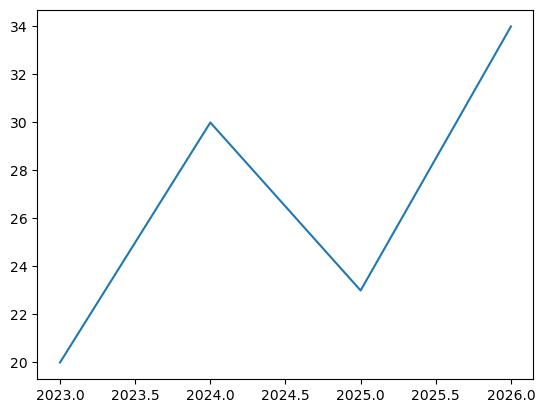

In [44]:
x=[2023, 2024, 2025, 2026]

y1=[20,30,23,34]

y2=[45,56,23,36]

y3=[34,12,23,65]

plt.plot(x,y1)

Uporabiti numpy array, ker so hitrejši.

In [ ]:
x=np.array([2023, 2024, 2025, 2026])

y=np.array([20,30,23,34])

plt.plot(x,y)

### Urejanje plot


Argumenti znotraj plot:

* `marker`: kako vizualizirati točke. Za celoten seznam glej dokumentacijo.
* `markersize` : velikost markerja
* `markerfacecolor` :barva markerja (ime barve, hex, rgb...)
* `markeregecolor` : barva obrobe markerja
* `linestyle` : stil črte 
    * 'solid', 'dashed', 'dashdot', 'dotted', 'None'
* `linewidth` : debelina črte
* `color` : barva črte

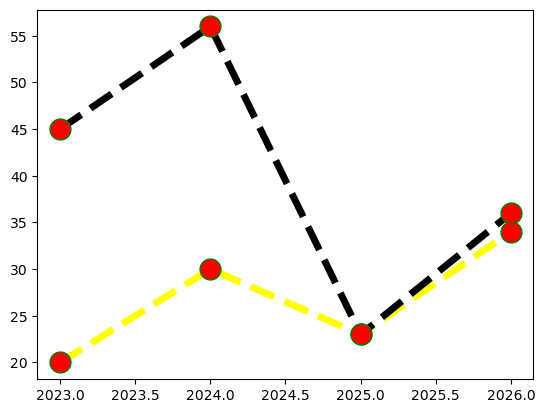

In [ ]:
plt.plot(x,y1, 
         marker=".",
         markersize=30,
         markerfacecolor="#FF0000",
         markeredgecolor="green",
         linestyle="dashed",
         linewidth=5,
         color="yellow")



stil_črte=dict(marker=".",
                markersize=30,
                markerfacecolor="#FF0000",
                markeredgecolor="green",
                linestyle="dashed",
                linewidth=5,
                )

plt.plot(x,y2, color="black", **stil_črte)  #če hočemo vnesti dict, ga je potrebno najprej unpack z **. Torej : spremeni v =.

plt.show()

### Label

`plt.title()` : naslov

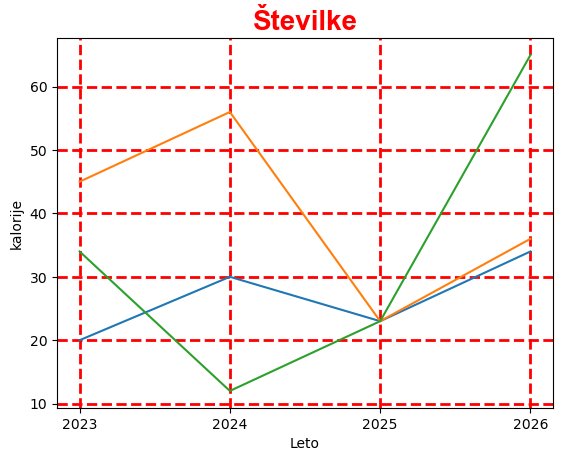

In [ ]:
plt.title("Številke",
          fontsize=20,      #Velikost naslova
          family="Arial",   #Font
          fontweight="bold",
          color="red",
          )  

plt.xlabel("Leto")
plt.ylabel("kalorije")

plt.xticks(x)  #vrednsoti na x

plt.tick_params("both", labelsize=10)  #urejanje vrednosti namesto both lahko tudi x ali y

plt.grid(axis="both",
         linewidth=2,
         color="red",
         linestyle="dashed")

plt.plot(x,y1)
plt.plot(x,y2)
plt.plot(x,y3)


### Barchart

`plt.bar` in `plt.barh` za horizontalene stolpce.

<BarContainer object of 4 artists>

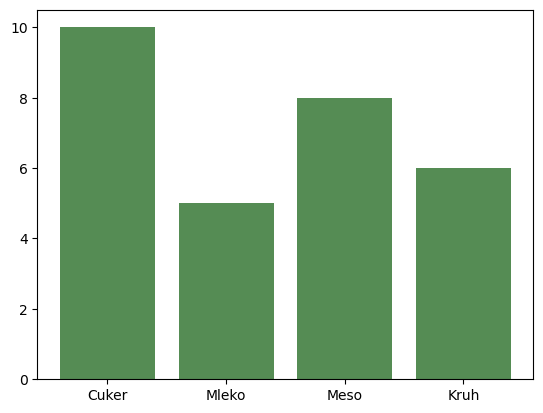

In [ ]:
katergorije=["Cuker", "Mleko", "Meso", "Kruh"]

vrednosti=np.array([10,5,8,6])

plt.bar(katergorije, vrednosti,   
        color= "#558c54",
        )

### Piechart

`plot.pie`

([<matplotlib.patches.Wedge at 0x1e3cc84b740>,
 [Text(-0.9718632975355646, 0.5152491930156696, 'Cuker'),
  Text(-0.46187825807823985, -0.9983328476588412, 'Mleko'),
  Text(0.910457896706755, -0.6173057737655724, 'Meso'),
  Text(0.8472436915863327, 1.1145304513862166, 'Kruh')],
 [Text(-0.530107253201217, 0.28104501437218343, '34.5%'),
  Text(-0.2519335953154035, -0.5445451896320952, '17.2%'),
  Text(0.4966133982036845, -0.3367122402357667, '27.6%'),
  Text(0.544656658876928, 0.7164838616054248, '20.7%')])

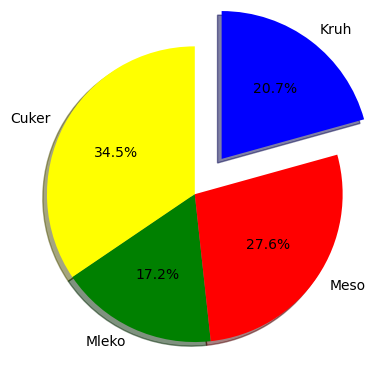

In [ ]:
katergorije=["Cuker", "Mleko", "Meso", "Kruh"]

vrednosti=np.array([10,5,8,6])

barve=["yellow", "green", "red", "blue"]

plt.pie( vrednosti,
        labels=katergorije,
        autopct="%1.1f%%",       # da automatsko napiše procente
        colors=barve,
        explode=[0,0,0,0.3],     # zamik dela
        shadow=True,
        startangle=90)      # da ga vrtiš

### Scater graphs


Za iskanje povezave med dvema spremenljivkama.

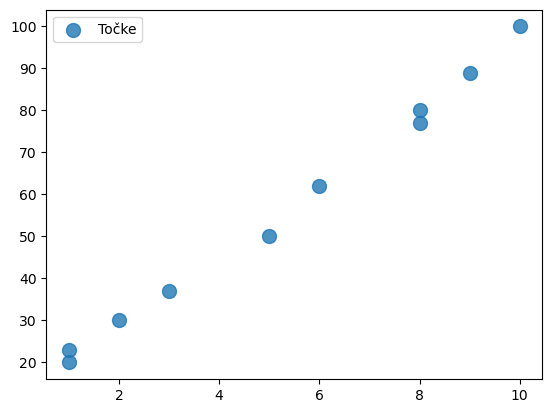

In [ ]:
ure=[1,1,2,3,5,6,8,8,9,10]

ocene=[20,23,30, 37, 50,62,77,80,89,100]

plt.scatter(ure, ocene,
            alpha=0.8,
            s=100,     #velikost
            label="Točke",    #za legendo
            )

plt.legend()    #da se doda legendo

### Histogram

Za vizualizacijo distribucije podatkov. Združi podatke v koše/intervale (stolpci).

(array([ 2.,  1.,  4.,  3.,  7.,  2.,  6.,  7.,  3.,  5.,  7.,  8., 13.,
         5.,  4.,  8.,  5.,  2.,  2.,  6.]),
 array([ 57.06078755,  59.20774817,  61.35470879,  63.50166942,
         65.64863004,  67.79559066,  69.94255128,  72.08951191,
         74.23647253,  76.38343315,  78.53039377,  80.6773544 ,
         82.82431502,  84.97127564,  87.11823626,  89.26519689,
         91.41215751,  93.55911813,  95.70607875,  97.85303938,
        100.        ]),
 <BarContainer object of 20 artists>)

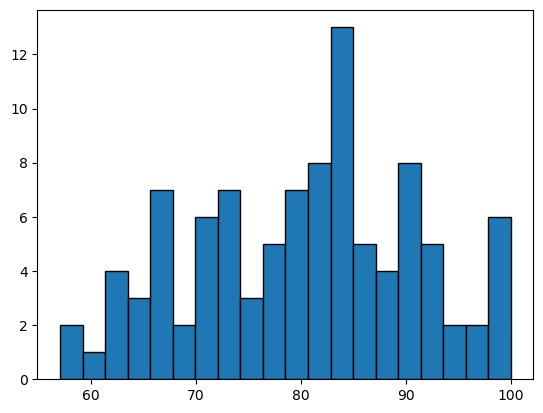

In [ ]:
rezultati=np.random.normal(loc=80, scale=10, size=100)  #generiranje naključnih števil z np.

rezultati=np.clip(rezultati,0,100)

plt.hist(rezultati, 
         bins=20,
         edgecolor="black",
         )

### Subplot

Figure je celotno platno.

Ax je en sam graf (plot).

`plt.subplot(2,2)` vrne dvojček za figure in za grafe. V tem primeru 2 grafa v vrsti in dva grafa v stolpcu.
Torej šterje grafi na enem platnu. 

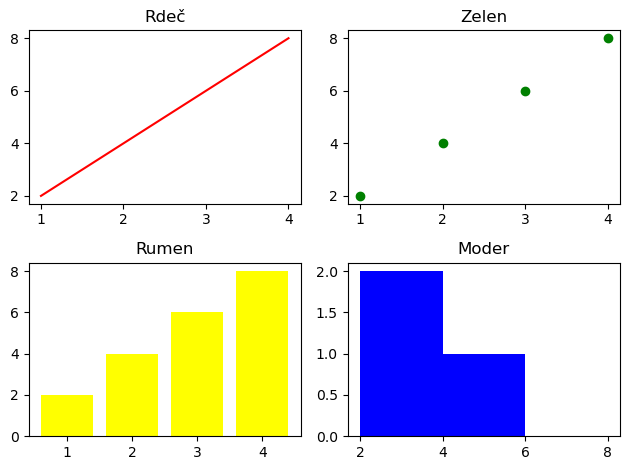

In [43]:
x=np.array([1,2,3,4])

figure, axes = plt.subplots(2,2) 

axes[0,0].plot(x,x*2, color="red")   # V [] je lokacije. V tem primeru prva vrstica, prvi stolpec
axes[0,0].set_title("Rdeč")

axes[0,1].scatter(x,x*2, color="green")  #[prva vrstica, drugi stolpec]
axes[0,1].set_title("Zelen")

axes[1,0].bar(x,x*2, color="yellow")
axes[1,0].set_title("Rumen")

axes[1,1].hist(x,x*2, color="blue")
axes[1,1].set_title("Moder")

plt.tight_layout()   #da pašejo lepo skupaj

### MatPlotLib + Pandas

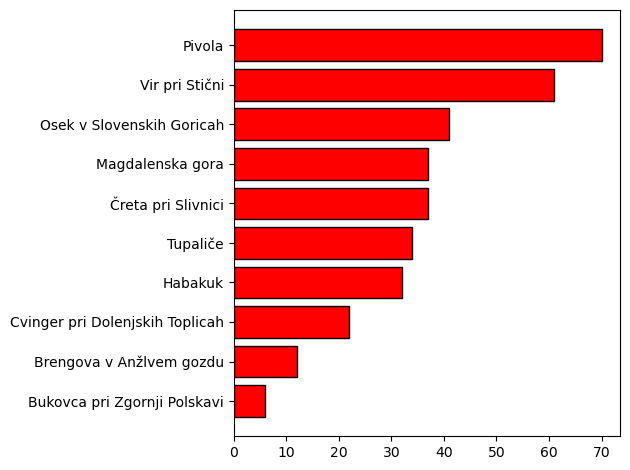

In [54]:
df= pd.read_csv(r"E:\Gomile - Vse gomile.csv", index_col="id", decimal=",")

Gomile=df["Najdišče"].value_counts(ascending=True)

plt.barh(Gomile.index, Gomile.values, 
        color="red",
        edgecolor="black")

plt.tight_layout()

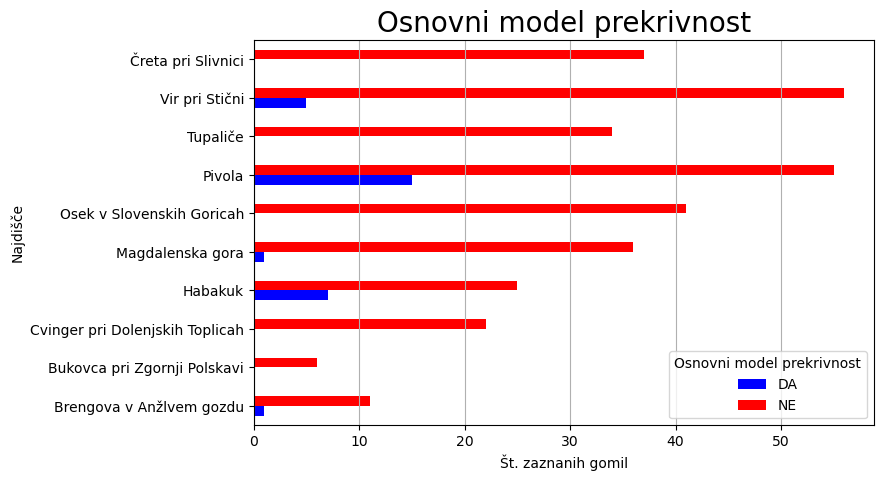

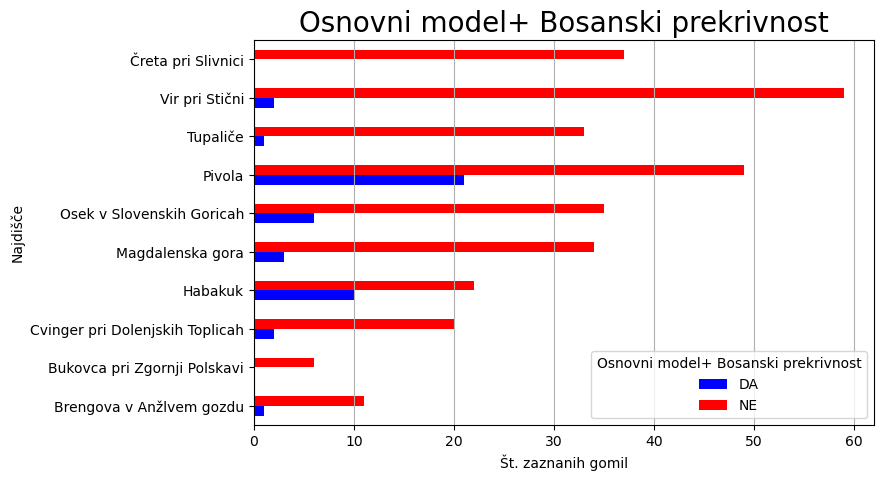

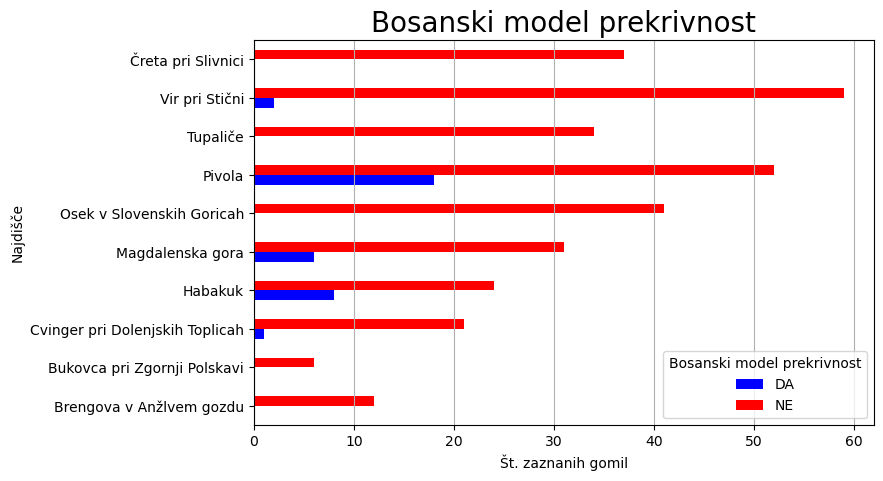

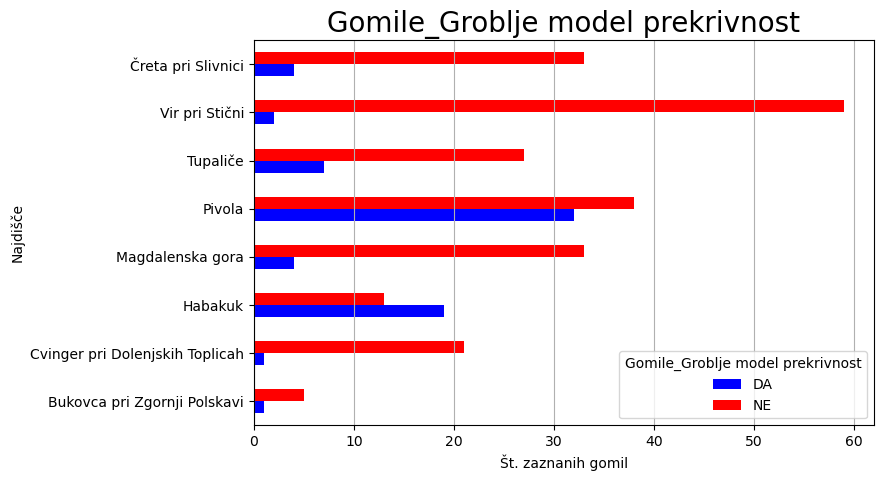

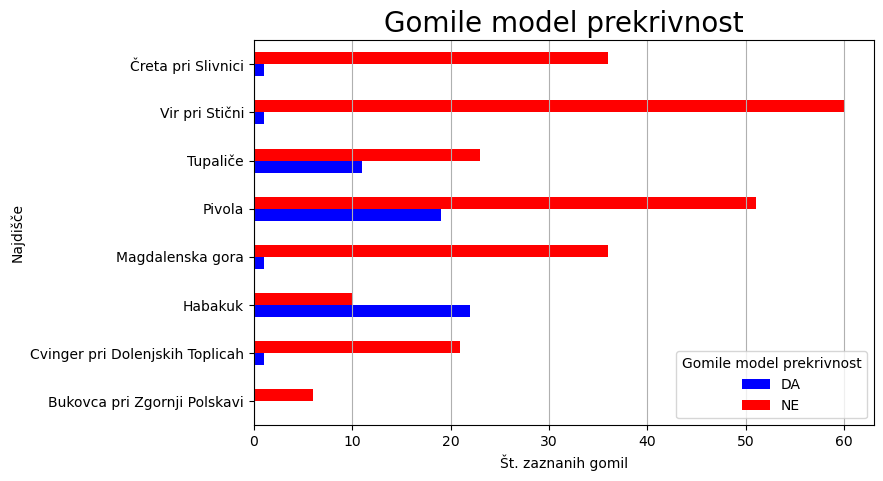

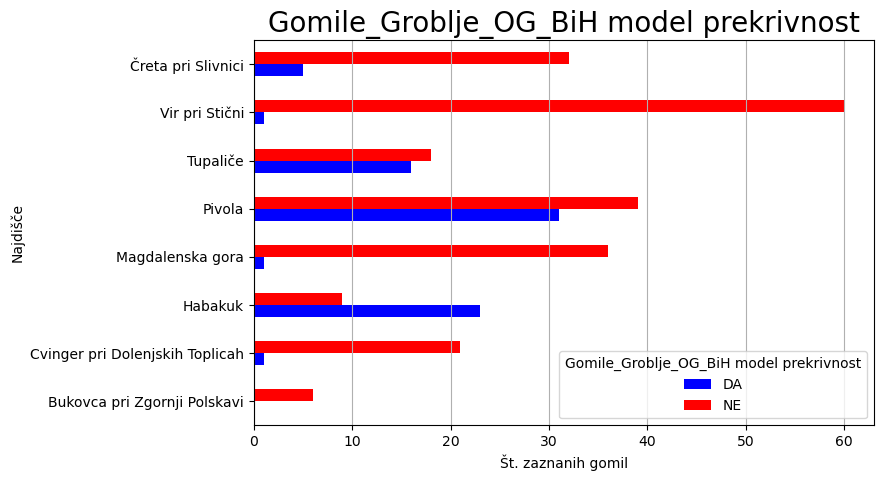

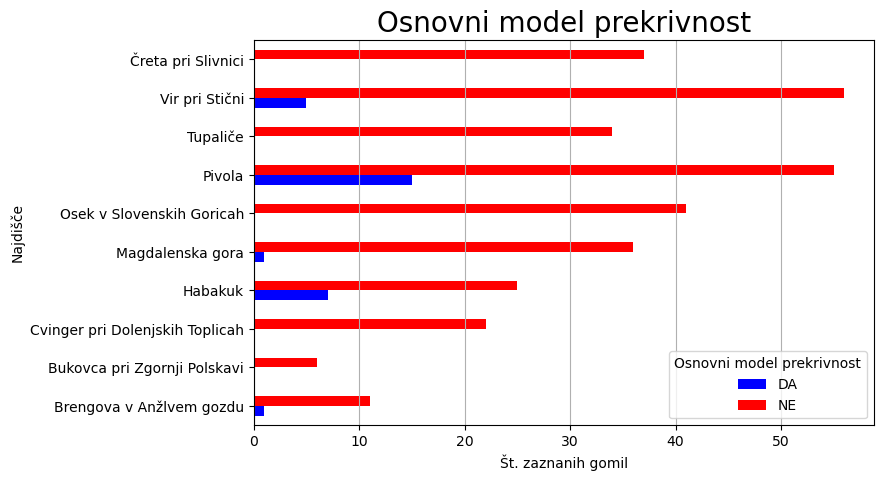

In [ ]:


modeli=[
"Osnovni model prekrivnost",
"Osnovni model+ Bosanski prekrivnost",
"Bosanski model prekrivnost",
"Gomile_Groblje model prekrivnost",
"Gomile model prekrivnost",
"Gomile_Groblje_OG_BiH model prekrivnost",
"Osnovni model prekrivnost"]

for i in modeli:
    št_zaznanih=df.groupby("Najdišče")[i].value_counts().unstack()
    

    #print(št_zaznanih)
   
    tabela=št_zaznanih.plot(kind="barh", 
                            color=["blue", "red"],
                            figsize=(8,5))

    # 'line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin'

    tabela.set_title(i, fontsize=20)
    tabela.set_xlabel("Št. zaznanih gomil")
    tabela.grid(axis="x")

    
  
    plt.savefig(rf"E:\testi vizualizacij\{i}.svg", bbox_inches="tight", dpi=300)
    